# 05 - Interprétation des résultats et recommandations

## Objectif

Ce notebook a pour objectif d'interpréter les résultats obtenus lors de l'évaluation des modèles de détection de fraude.

Il vise à transformer les résultats du Machine Learning en informations exploitables pour la prise de décision.

## Axes d'analyse

1. Identification des caractéristiques les plus importantes pour le modèle.
2. Analyse de la répartition des fraudes selon les types de transactions.
3. Analyse des erreurs de classification.
4. Comparaison avec le système de détection existant.
5. Formulation de recommandations opérationnelles.

## Finalité

Le modèle constitue un outil d'aide à la détection des transactions suspectes. Il ne doit pas remplacer entièrement les mécanismes de contrôle et de vérification humains.

Importation des bibliothèques

In [13]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.inspection import permutation_importance

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


Chargement des modèles et des résultats

In [14]:
# Recherche du répertoire principal
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "notebooks").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Dossier du projet introuvable.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Définition des répertoires
MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"

# Chargement du modèle retenu
selected_model = joblib.load(
    MODEL_DIR / "random_forest.pkl"
)

# Chargement du seuil retenu
selected_threshold = joblib.load(
    MODEL_DIR / "selected_threshold.pkl"
)

# Chargement des données
valid = pd.read_parquet(DATA_DIR / "valid.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")

# Chargement des prédictions finales
test_predictions = pd.read_parquet(
    RESULTS_DIR / "predictions_test.parquet"
)

# Variables explicatives
features = [
    "transaction_type",
    "amount",
    "heure",
    "tranche_horaire",
    "type_jour",
    "orig_type",
    "dest_type"
]

X_valid = valid[features]
y_valid = valid["is_fraud"]

print("Chargement terminé.")
print("Seuil retenu :", selected_threshold)
print("Données de validation :", valid.shape)
print("Données de test :", test.shape)

Chargement terminé.
Seuil retenu : 0.9000000000000002
Données de validation : (45896, 10)
Données de test : (44216, 10)


Importance des caractéristiques du modèle

In [15]:
# Récupération du préprocesseur et du classificateur
preprocessor = selected_model.named_steps["preprocessor"]
classifier = selected_model.named_steps["classifier"]

# Récupération des noms des variables après transformation
feature_names = preprocessor.get_feature_names_out()

# Importance calculée par les arbres du Random Forest
importances = classifier.feature_importances_

# Création du tableau
feature_importance = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
})

# Classement décroissant
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15).round(4))

,Variable,Importance
0,num__amount,0.3569
6,cat__transaction_type_TRANSFER,0.1366
1,num__heure,0.1328
2,cat__transaction_type_CASH_IN,0.0879
14,cat__dest_type_Client,0.0723
3,cat__transaction_type_CASH_OUT,0.0572
15,cat__dest_type_Commerçant,0.0499
5,cat__transaction_type_PAYMENT,0.0496
9,cat__tranche_horaire_Nuit,0.0331
7,cat__tranche_horaire_Après-midi,0.0084


Visualisation des caractéristiques importantes

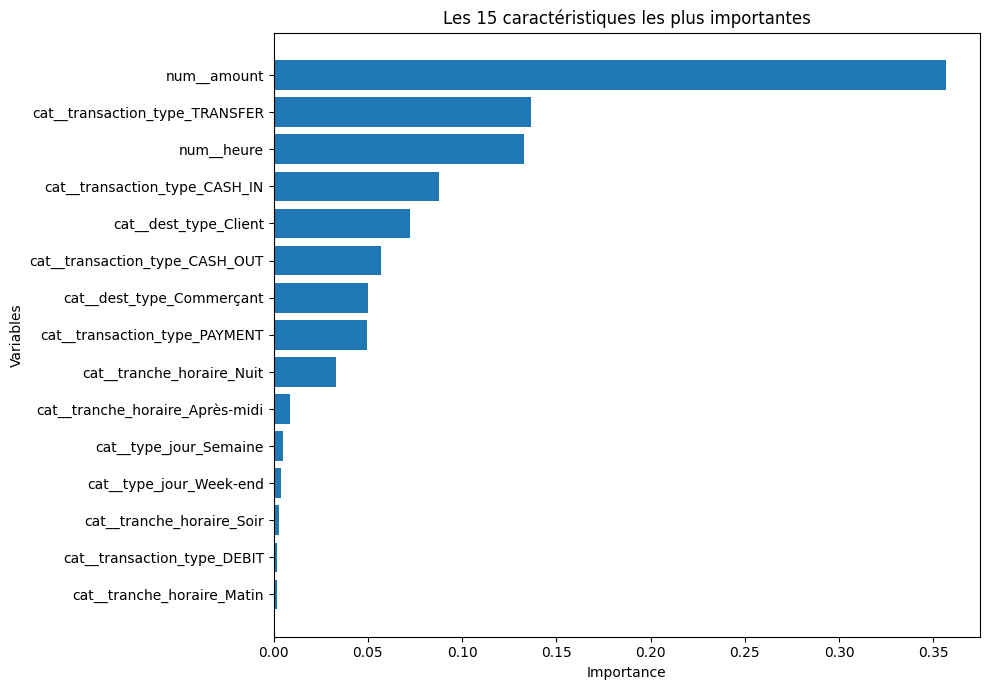

In [16]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Variable"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Variables")
plt.title("Les 15 caractéristiques les plus importantes")
plt.tight_layout()
plt.show()

Importance des variables par permutation

In [17]:
permutation_result = permutation_importance(
    selected_model,
    X_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Variable": features,
    "Importance_moyenne": permutation_result.importances_mean,
    "Ecart_type": permutation_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance_moyenne",
    ascending=False
)

display(permutation_importance_df.round(4))

,Variable,Importance_moyenne,Ecart_type
0,transaction_type,0.3713,0.0042
1,amount,0.3640,0.0035
2,heure,0.1651,0.0030
6,dest_type,0.1049,0.0119
3,tranche_horaire,0.0931,0.0044
4,type_jour,0.0095,0.0019
5,orig_type,0.0000,0.0000


Analyse des fraudes par type de transaction

In [18]:
fraud_by_type = test.groupby("transaction_type").agg(
    transactions=("is_fraud", "count"),
    fraudes=("is_fraud", "sum")
)

fraud_by_type["transactions_normales"] = (
    fraud_by_type["transactions"] - fraud_by_type["fraudes"]
)

fraud_by_type["taux_fraude"] = (
    fraud_by_type["fraudes"] /
    fraud_by_type["transactions"] * 100
)

fraud_by_type = fraud_by_type.sort_values(
    by="fraudes",
    ascending=False
)

display(fraud_by_type.round(2))

,transactions,fraudes,transactions_normales,taux_fraude
transaction_type,,,,
TRANSFER,5430,1995,3435,36.74
CASH_OUT,15477,1982,13495,12.81
CASH_IN,8953,0,8953,0.00
DEBIT,291,0,291,0.00
PAYMENT,14065,0,14065,0.00


Visualisation de la répartition des fraudes

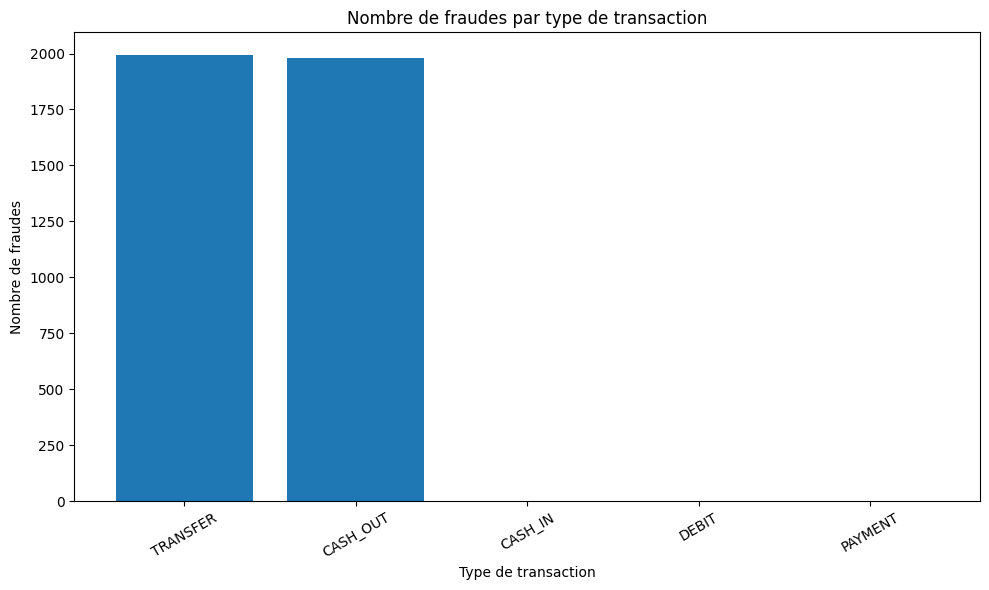

In [19]:
plt.figure(figsize=(10, 6))

plt.bar(
    fraud_by_type.index,
    fraud_by_type["fraudes"]
)

plt.xlabel("Type de transaction")
plt.ylabel("Nombre de fraudes")
plt.title("Nombre de fraudes par type de transaction")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Nous pouvons également visualiser les taux de fraude :

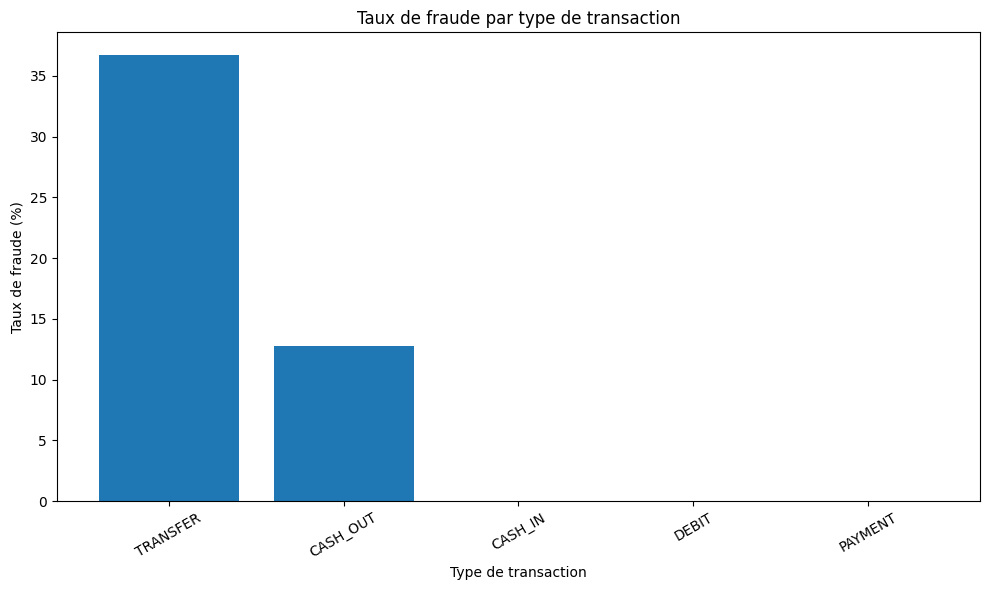

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    fraud_by_type.index,
    fraud_by_type["taux_fraude"]
)

plt.xlabel("Type de transaction")
plt.ylabel("Taux de fraude (%)")
plt.title("Taux de fraude par type de transaction")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Analyse des erreurs du modèle

In [21]:
# Création du tableau d'analyse
error_analysis = test.copy()

error_analysis["predicted_fraud"] = test_predictions["y_pred"].values

error_analysis["fraud_probability"] = (
    test_predictions["fraud_probability"].values
)

# Identification des erreurs
error_analysis["prediction_status"] = np.select(
    [
        (error_analysis["is_fraud"] == 1) &
        (error_analysis["predicted_fraud"] == 1),

        (error_analysis["is_fraud"] == 0) &
        (error_analysis["predicted_fraud"] == 0),

        (error_analysis["is_fraud"] == 0) &
        (error_analysis["predicted_fraud"] == 1),

        (error_analysis["is_fraud"] == 1) &
        (error_analysis["predicted_fraud"] == 0)
    ],
    [
        "Vraie fraude détectée",
        "Transaction normale correctement classée",
        "Fausse alerte",
        "Fraude non détectée"
    ],
    default="Autre"
)

display(error_analysis["prediction_status"].value_counts())

prediction_status
Transaction normale correctement classée    40063
Fraude non détectée                          2103
Vraie fraude détectée                        1874
Fausse alerte                                 176
Name: count, dtype: int64

Nous allons ensuite examiner les fausses alertes et les fraudes non détectées.

In [22]:
errors = error_analysis[
    error_analysis["prediction_status"].isin([
        "Fausse alerte",
        "Fraude non détectée"
    ])
]

error_summary = errors.groupby(
    ["prediction_status", "transaction_type"]
).size().unstack(fill_value=0)

display(error_summary)

transaction_type,CASH_OUT,TRANSFER
prediction_status,,
Fausse alerte,63,113
Fraude non détectée,888,1215


Formulation des recommandations métier
Voici les recommandations que nous pouvons envisager à partir de notre étude.

# Recommandations opérationnelles

## 1. Renforcer la surveillance des opérations sensibles

Les résultats de l'analyse montrent que les opérations TRANSFER et CASH_OUT concentrent une part importante des fraudes observées.

Il est recommandé de renforcer leur surveillance en utilisant plusieurs caractéristiques des transactions, plutôt que de considérer automatiquement ces opérations comme suspectes.

## 2. Mettre en place un système d'alertes graduées

Les transactions peuvent être réparties en plusieurs niveaux de risque selon leur probabilité de fraude.

- Risque faible : traitement normal.
- Risque intermédiaire : vérification complémentaire.
- Risque élevé : alerte prioritaire et examen par un agent habilité.

Les seuils doivent être définis en fonction des coûts des fraudes et des conséquences des fausses alertes.

## 3. Maintenir une validation humaine

Le modèle doit être considéré comme un outil d'aide à la décision.

Une transaction signalée comme suspecte ne doit pas être automatiquement considérée comme frauduleuse. Les situations sensibles doivent faire l'objet d'une vérification complémentaire.

## 4. Améliorer continuellement le modèle

Les comportements frauduleux peuvent évoluer.

Il est donc recommandé de suivre régulièrement les performances du modèle, d'analyser les nouvelles fraudes et de réentraîner le système lorsque cela est justifié.

## 5. Surveiller les erreurs de classification

Les faux positifs et les faux négatifs doivent être étudiés régulièrement.

Cette analyse permettra d'améliorer progressivement le système tout en limitant les désagréments pour les clients honnêtes.

# Conclusion générale du projet

Ce projet a permis de mettre en place une chaîne de traitement et d'analyse des transactions Mobile Money dans le but de développer un système de détection des fraudes.

La démarche a couvert plusieurs étapes :

- Exploration et compréhension des données.
- Préparation des données et création des ensembles d'entraînement, de validation et de test.
- Conception et entraînement de modèles de classification.
- Évaluation et comparaison des performances.
- Interprétation des résultats et formulation de recommandations.

Les expérimentations ont permis d'étudier les capacités de la régression logistique et du Random Forest à identifier les transactions frauduleuses.

L'analyse des caractéristiques et des erreurs de classification permet également de mieux comprendre le comportement du modèle et ses limites.

Toutefois, les résultats doivent être interprétés avec prudence. PaySim repose sur des données synthétiques et notre jeu de données a fait l'objet d'un échantillonnage. De plus, des différences importantes de distribution ont été observées entre les périodes.

Le système développé constitue donc une solution expérimentale d'aide à la détection des transactions suspectes. Son utilisation dans un environnement réel nécessiterait une validation sur des données opérationnelles, un suivi continu des performances et une adaptation aux contraintes métier.

L'objectif final est de contribuer à une détection plus efficace des fraudes tout en limitant les blocages injustifiés des transactions légitimes.